In [ ]:
!pip install pandas numpy matplotlib seaborn

# Apollo Hospital Appointment Analysis

### Business Insights, Patient Attendance, Revenue & Doctor Utilisation

**Project overview:** This notebook explores Apollo appointment data to understand appointment trends, no-show behaviour, reminder effectiveness, patient segments, revenue patterns, and doctor service quality. The original analysis is retained, with a small executive snapshot added at the beginning.

**Data files required:** `apollo_appointments_fact.csv` and `apollo_doctors_dim.csv` should be placed inside the `data/` folder of this repository.


## Business Problem

Hospitals need to manage appointments efficiently to provide better patient care and use their resources effectively. Missed appointments (no-shows), cancellations, and long waiting times can affect hospital operations and revenue. Understanding appointment patterns and patient attendance can help identify areas where operational improvements may be needed.

This project analyses Apollo Hospital appointment data to explore patient attendance, appointment trends, reminder effectiveness, financial performance, and doctor utilisation.

## Project Objectives

- Analyse appointment volume and appointment outcomes over time.
- Identify patient groups, specialties, cities, and booking patterns associated with higher no-show rates.
- Evaluate the relationship between appointment reminders, previous attendance behaviour, and no-shows.
- Examine revenue patterns, estimated revenue loss from no-shows, and patient payment behaviour.
- Assess doctor utilisation, patient waiting times, consultation duration, and patient satisfaction.

## Tools Used

- **Python:** Main programming language for data analysis.
- **Pandas:** Data cleaning, data manipulation, and aggregation.
- **NumPy:** Numerical calculations and data analysis.
- **Matplotlib:** Creating charts and visualisations.
- **Seaborn:** Creating statistical visualisations.

## Key Business Questions

1. How do appointment volumes and appointment outcomes change over time?
2. Which specialties, cities, booking channels, and appointment patterns are associated with higher no-show rates?
3. Are appointment reminders and previous patient attendance associated with better attendance?
4. How do no-shows affect revenue, and how do revenue and patient payments vary across specialties and cities?
5. How efficiently are doctors utilised, and what patterns exist in patient waiting times, consultation duration, and satisfaction?

## Expected Business Value

The analysis aims to provide data-driven insights that may help Apollo Hospital identify potential improvements in appointment management, patient engagement, revenue planning, and resource utilisation.

The findings describe patterns and associations in the available data; they do not by themselves prove that a particular factor causes no-shows or changes patient satisfaction.

## How to Run

1. Install the libraries: `pip install -r requirements.txt` (or run the first cell below).
2. Put `apollo_appointments_fact.csv` and `apollo_doctors_dim.csv` in a `data/` folder next to this notebook, or change `DATA_DIR` in the data-loading cell.
3. Run all cells from top to bottom (**Kernel → Restart & Run All**).

## Dataset Overview

This project uses appointment-related data to explore patient attendance, appointment outcomes, revenue patterns, and hospital operations.

The analysis examines relevant information such as appointment status, patient characteristics, appointment timing, reminders, specialty, financial measures, and doctor utilisation, where available in the dataset.

### Data Preparation

The appointment and doctor datasets are loaded into Pandas DataFrames. The `appointment_date` column is converted to datetime format, and additional columns for appointment year and month name are created to support time-based analysis.

In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt 
import seaborn as sns 
# Change DATA_DIR if your CSV files are in another folder, e.g. r"D:\apollo"
DATA_DIR = "data"

data = pd.read_csv(f"{DATA_DIR}/apollo_appointments_fact.csv")
Appointment_data = pd.DataFrame(data)

Data = pd.read_csv(f"{DATA_DIR}/apollo_doctors_dim.csv")
Apollo_doctor = pd.DataFrame(Data)
Appointment_data["appointment_date"] = pd.to_datetime(Appointment_data["appointment_date"], format="mixed")
Appointment_data["Appointment_Year"]=Appointment_data["appointment_date"].dt.year
Appointment_data["Appointment_MonthName"]=Appointment_data["appointment_date"].dt.month_name()


## Quick Business Snapshot

This section gives a quick overview of the dataset before moving into the detailed analysis. Rates are calculated from the appointment status field.

In [2]:
# Basic dataset-level KPIs
total_appointments = len(Appointment_data)
unique_patients = Appointment_data["patient_id"].nunique()
completed_appointments = (Appointment_data["appointment_status"] == "Completed").sum()
no_show_appointments = (Appointment_data["appointment_status"] == "No-Show").sum()
cancelled_appointments = (Appointment_data["appointment_status"] == "Cancelled").sum()

snapshot = pd.DataFrame({
    "Metric": [
        "Total Appointments", "Unique Patients", "Completed Appointments",
        "No-Show Appointments", "Cancelled Appointments", "Completion Rate (%)",
        "No-Show Rate (%)"
    ],
    "Value": [
        total_appointments,
        unique_patients,
        completed_appointments,
        no_show_appointments,
        cancelled_appointments,
        round(completed_appointments / total_appointments * 100, 2) if total_appointments else 0,
        round(no_show_appointments / total_appointments * 100, 2) if total_appointments else 0
    ]
})

snapshot

,Metric,Value
0,Total Appointments,75000.00
1,Unique Patients,32705.00
2,Completed Appointments,55275.00
3,No-Show Appointments,11584.00
4,Cancelled Appointments,5793.00
5,Completion Rate (%),73.70
6,No-Show Rate (%),15.45


In [3]:
Appointment_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 75000 entries, 0 to 74999
Data columns (total 54 columns):
 #   Column                      Non-Null Count  Dtype         
---  ------                      --------------  -----         
 0   appointment_id              75000 non-null  str           
 1   patient_id                  75000 non-null  str           
 2   doctor_id                   75000 non-null  str           
 3   appointment_date            75000 non-null  datetime64[us]
 4   appointment_day             75000 non-null  str           
 5   appointment_day_of_week     75000 non-null  int64         
 6   appointment_month           75000 non-null  int64         
 7   appointment_quarter         75000 non-null  str           
 8   appointment_year            75000 non-null  int64         
 9   appointment_hour            75000 non-null  int64         
 10  appointment_minute          75000 non-null  int64         
 11  time_slot                   75000 non-null  str           
 12  t

In [4]:
Apollo_doctor.info()

<class 'pandas.DataFrame'>
RangeIndex: 320 entries, 0 to 319
Data columns (total 15 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   doctor_id              320 non-null    str    
 1   doctor_name            320 non-null    str    
 2   specialty              320 non-null    str    
 3   qualification          320 non-null    str    
 4   experience_years       320 non-null    int64  
 5   city                   320 non-null    str    
 6   state                  320 non-null    str    
 7   hospital_name          320 non-null    str    
 8   consultation_fee       320 non-null    int64  
 9   rating                 320 non-null    float64
 10  total_reviews          320 non-null    int64  
 11  available_days         320 non-null    str    
 12  avg_slot_duration_min  320 non-null    int64  
 13  accepts_insurance      320 non-null    str    
 14  teleconsult_enabled    320 non-null    str    
dtypes: float64(1), in

# Business Overview

## 1. How is appointment volume trending across months and quarters from 2022 to 2024?

In [5]:

# Convert appointment date to datetime
Appointment_data["appointment_date"] = pd.to_datetime(
    Appointment_data["appointment_date"], errors="coerce"
)

# Filter data from 2022 to 2024
trend_data = Appointment_data[
    Appointment_data["appointment_date"].dt.year.between(2022, 2024)
].copy()

# Monthly appointment volume
trend_data["month"] = trend_data["appointment_date"].dt.to_period("M")

Monthly_volume = trend_data.groupby(
    "month"
).size().reset_index(name="total_appointments")

Monthly_volume["month"] = Monthly_volume["month"].astype(str)

# Quarterly appointment volume
trend_data["quarter"] = trend_data["appointment_date"].dt.to_period("Q")

Quarterly_volume = trend_data.groupby(
    "quarter"
).size().reset_index(name="total_appointments")

Quarterly_volume["quarter"] = Quarterly_volume["quarter"].astype(str)

print("Monthly Appointment Volume")
display(Monthly_volume)

print("Quarterly Appointment Volume")
display(Quarterly_volume)


Monthly Appointment Volume


,month,total_appointments
0,2022-01,2426
1,2022-02,2012
2,2022-03,2085
3,2022-04,1926
4,2022-05,2033
5,2022-06,1823
6,2022-07,1833
7,2022-08,1835
8,2022-09,2115
9,2022-10,2206


Quarterly Appointment Volume


,quarter,total_appointments
0,2022Q1,6523
1,2022Q2,5782
2,2022Q3,5783
3,2022Q4,6780
4,2023Q1,6487
5,2023Q2,5862
6,2023Q3,5707
7,2023Q4,6998
8,2024Q1,6538
9,2024Q2,5899


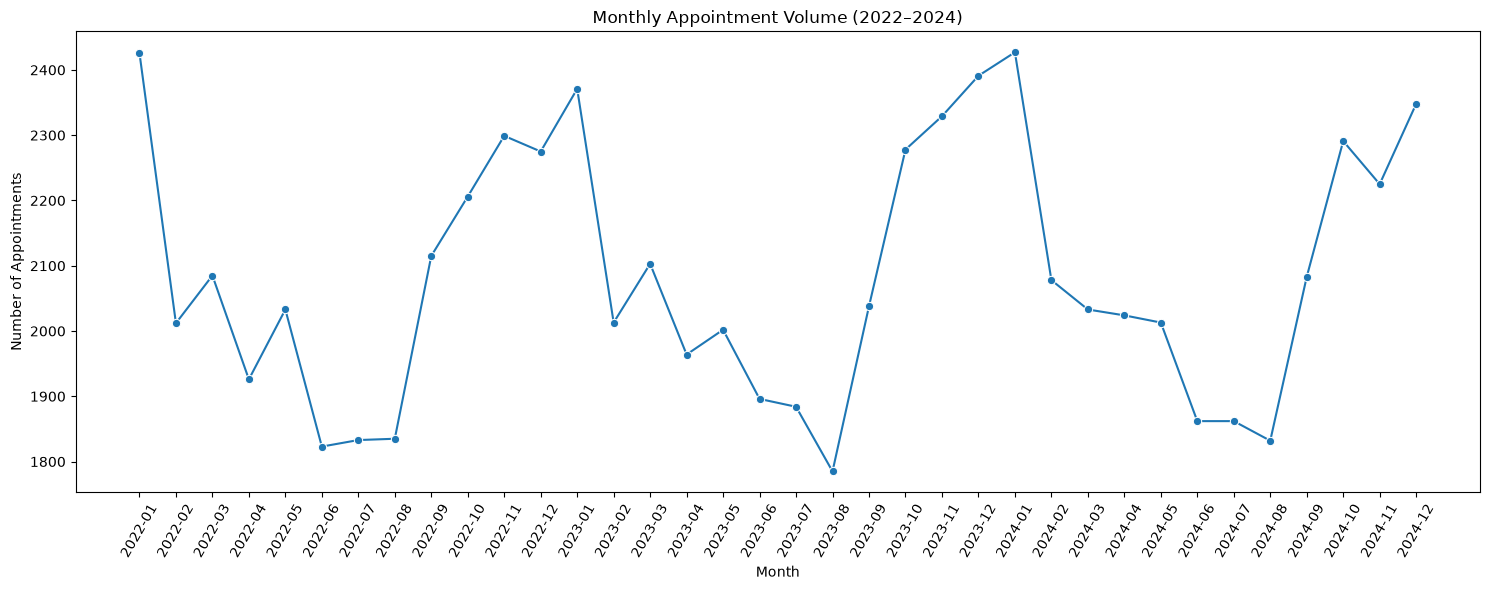

In [6]:
#Monthly trend visualization

plt.figure(figsize=(15, 6))

sns.lineplot(
    data=Monthly_volume,
    x="month",
    y="total_appointments",
    marker="o"
)

plt.title("Monthly Appointment Volume (2022–2024)")
plt.xlabel("Month")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=60)
plt.tight_layout()
plt.show()


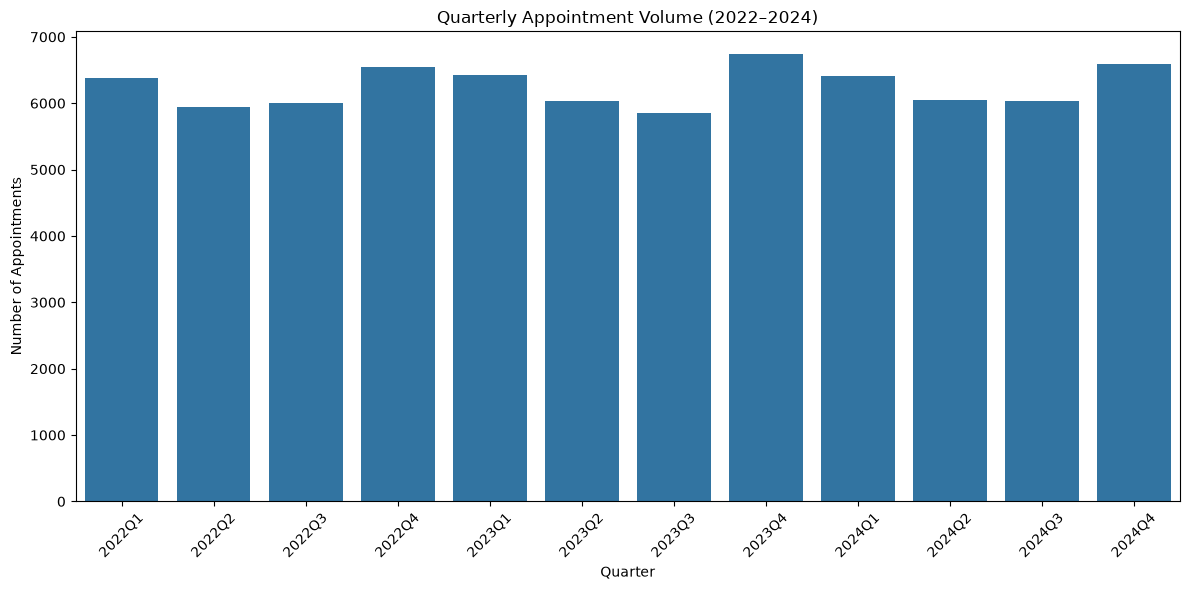

In [77]:
#Quarterly trend visualization

plt.figure(figsize=(12, 6))

sns.barplot(
    data=Quarterly_volume,
    x="quarter",
    y="total_appointments",
    errorbar=None
)

plt.title("Quarterly Appointment Volume (2022–2024)")
plt.xlabel("Quarter")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 📌 Insight
- Volume is stable at about **25,000 appointments a year** (24,868 in 2022, 25,054 in 2023, 25,078 in 2024).
- Demand is seasonal: **Q4 is the busiest quarter** each year (peak 6,746 in 2023 Q4) and **Q3 the quietest** (lowest 5,852 in 2023 Q3). December 2023 is the busiest month (2,342).

## 2.What is the split of outcomes across completed, no-show, cancelled, and scheduled appointments? 

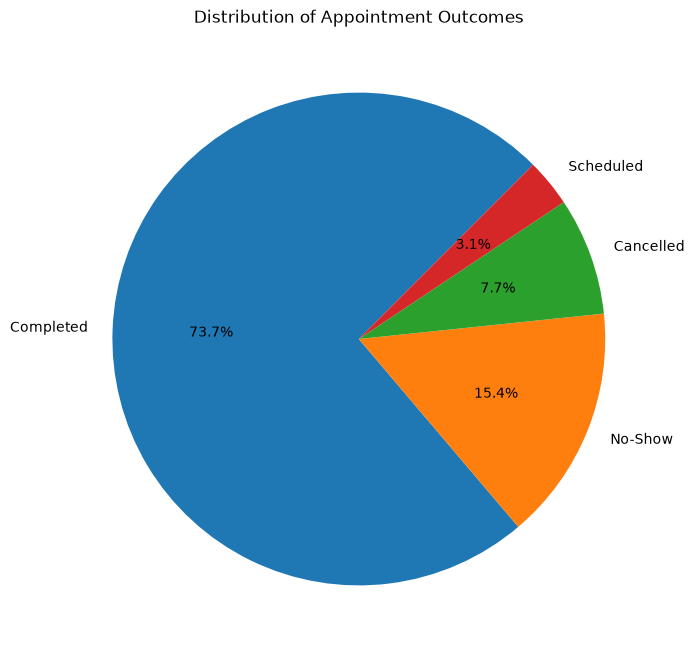

In [7]:
status_counts = Appointment_data["appointment_status"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=45
)
plt.title("Distribution of Appointment Outcomes")

plt.show()



### 📌 Insight
- **73.70%** of appointments are completed, **15.45%** are no-shows (11,584), **7.72%** are cancelled (5,793) and **3.13%** are still scheduled.

## 3.Which booking channels drive the highest volume and how does the channel mix look? 

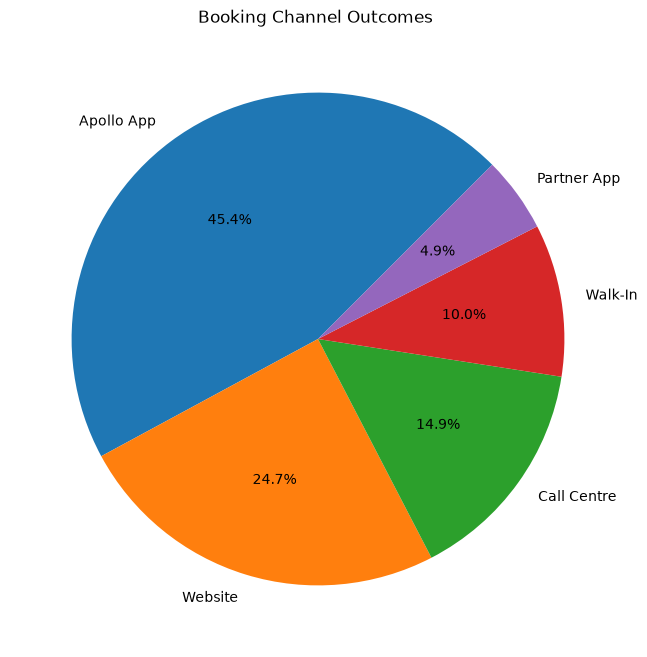

In [8]:
Appointment_data["booking_channel"]
channel_count=Appointment_data["booking_channel"].value_counts()
plt.figure(figsize=(8,8))
plt.pie(channel_count.values,
       labels=channel_count.index,
        autopct="%1.1f%%",
        startangle=45
       )
plt.title("Booking Channel Outcomes ")
plt.show()


### 📌 Insight
- **Apollo App** is the largest booking channel by volume (32,958 eligible appointments), well ahead of Website (17,964) and Call Centre (10,855).

## No-Show Analysis 

 ## 1. Which specialties and cities have the highest and lowest no-show rates? 

In [11]:
eligible_appointments = Appointment_data[
    Appointment_data["appointment_status"].isin(
        ["Completed", "No-Show", "Cancelled"]
    )
].copy()
specialty_summary = eligible_appointments.pivot_table(
    index=["specialty"],
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

specialty_summary.columns = ["Total_Eligible", "Total_No_Shows"]

specialty_summary["No_Show_Rate"] = (
    specialty_summary["Total_No_Shows"]
    / specialty_summary["Total_Eligible"]
) * 100

specialty_summary = specialty_summary.sort_values(
    "No_Show_Rate", ascending=False
)

specialty_summary

,Total_Eligible,Total_No_Shows,No_Show_Rate
specialty,,,
Psychiatry,2900,711,24.517241
Dermatology,7566,1608,21.252974
ENT,5211,988,18.959893
Endocrinology,2024,355,17.539526
Ophthalmology,3103,503,16.210119
General Physician,19654,3049,15.513381
Pulmonology,2549,394,15.457042
Orthopaedics,5419,810,14.947407
Gastroenterology,2527,377,14.918876


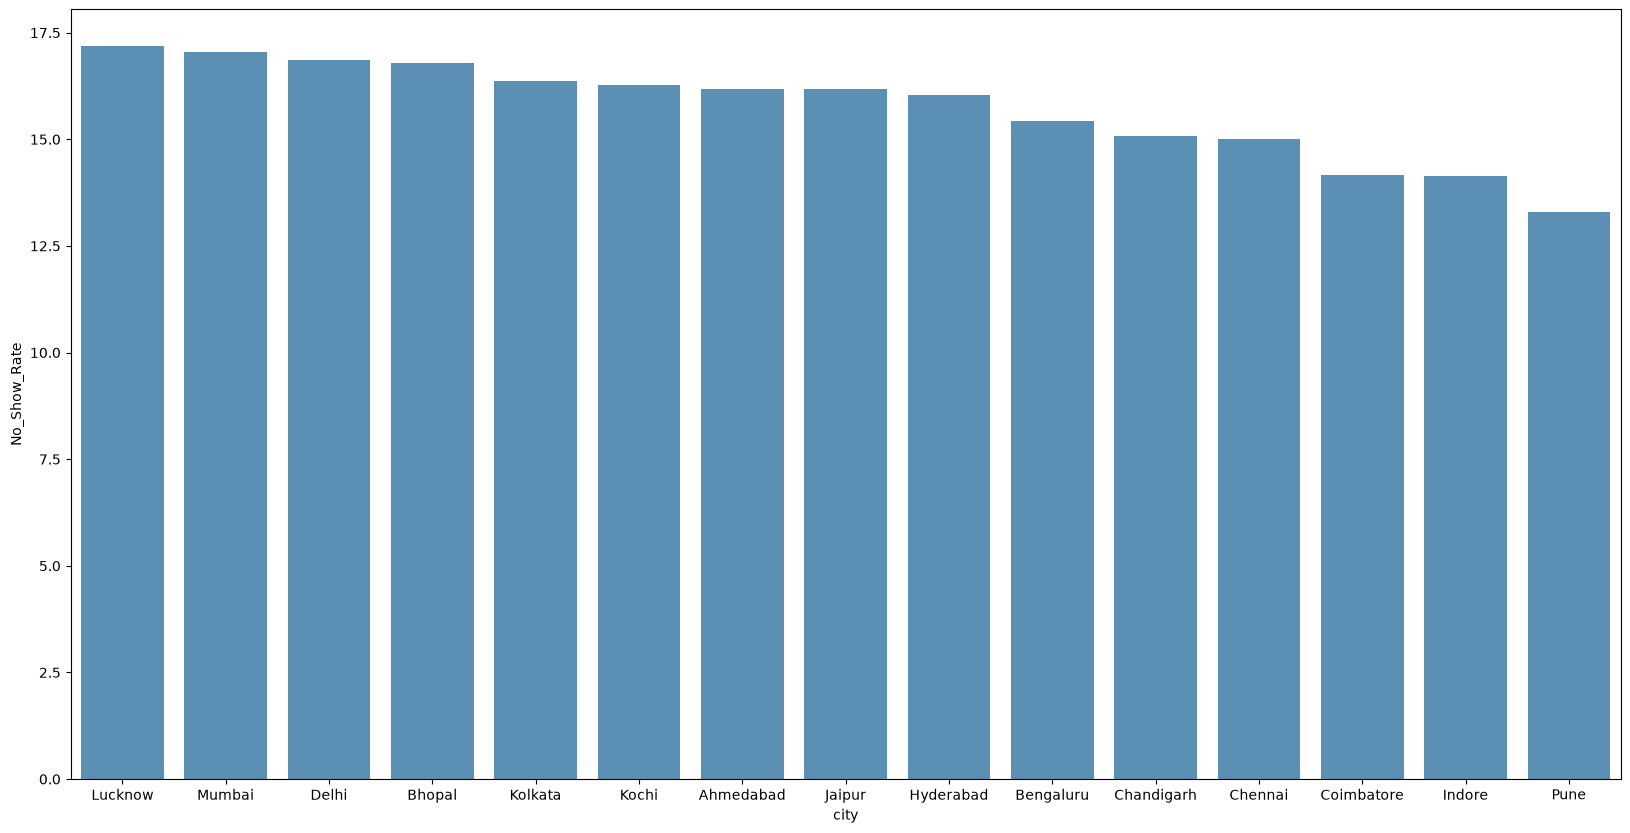

In [12]:
city_summary = eligible_appointments.pivot_table(
    index="city",
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

city_summary.columns = ["Total_Eligible", "Total_No_Shows"]

city_summary["No_Show_Rate"] = (
    city_summary["Total_No_Shows"]
    / city_summary["Total_Eligible"]
) * 100

city_summary = city_summary.sort_values(
    "No_Show_Rate", ascending=False
).reset_index()\


plt.figure(figsize=(20,10))
sns.barplot(
    data=city_summary,
    x="city",
    y="No_Show_Rate",
    alpha=0.8
)

plt.show()

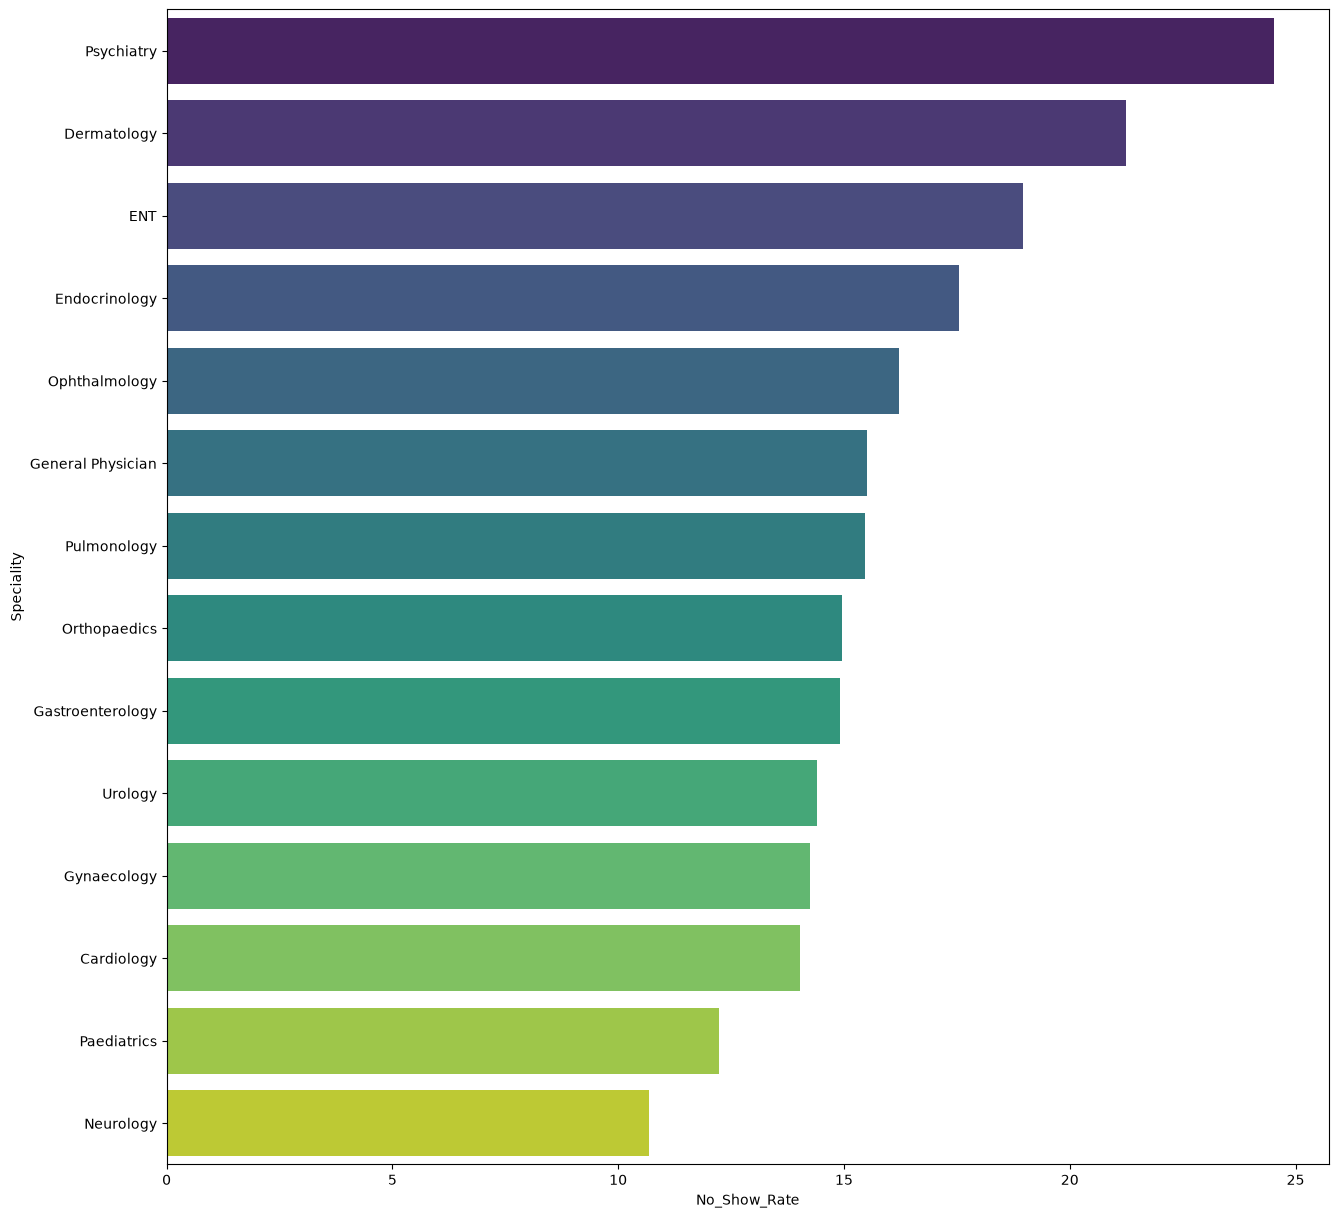

In [13]:
specialty_summary

plt.figure(figsize=(15,15))
sns.barplot(
    data=specialty_summary,
    x="No_Show_Rate",
    y="specialty",
    hue="specialty",
    palette="viridis",
    legend=False
)
plt.ylabel("Speciality")
plt.show()

### 📌 Insight
- Highest no-show rates: **Psychiatry 24.5%**, **Dermatology 21.3%**, **ENT 19.0%**.
- Lowest: **Neurology 10.7%**, **Paediatrics 12.2%**, **Cardiology 14.0%**.
- By city, Lucknow, Mumbai and Delhi are highest (about 17%) and Pune is lowest (about 13%).

## 2.How does booking lead time affect the probability of a no-show? 

In [83]:

# Create booking lead-time groups
bins = [0, 1, 7, 14, 30, float("inf")]

labels = [
    "0–1 days",
    "2–7 days",
    "8–14 days",
    "15–30 days",
    "More than 30 days"
]

eligible_appointments["Lead_Time_Group"] = pd.cut(
    eligible_appointments["booking_lead_days"],
    bins=bins,
    labels=labels
)

# Calculate eligible appointments and no-show counts
lead_time_summary = eligible_appointments.groupby(
    "Lead_Time_Group", observed=False
).agg(
    Total_Eligible=("no_show_flag", "count"),
    Total_No_Shows=("no_show_flag", "sum")
)

# Calculate observed no-show probability as a percentage
lead_time_summary["No_Show_Probability"] = (
    lead_time_summary["Total_No_Shows"]
    / lead_time_summary["Total_Eligible"]
) * 100

# Display the summary table
lead_time_summary


,Total_Eligible,Total_No_Shows,No_Show_Probability
Lead_Time_Group,,,
0–1 days,10453,1382,13.221085
2–7 days,30919,4892,15.821986
8–14 days,8758,1648,18.817082
15–30 days,2342,469,20.025619
More than 30 days,0,0,NaN


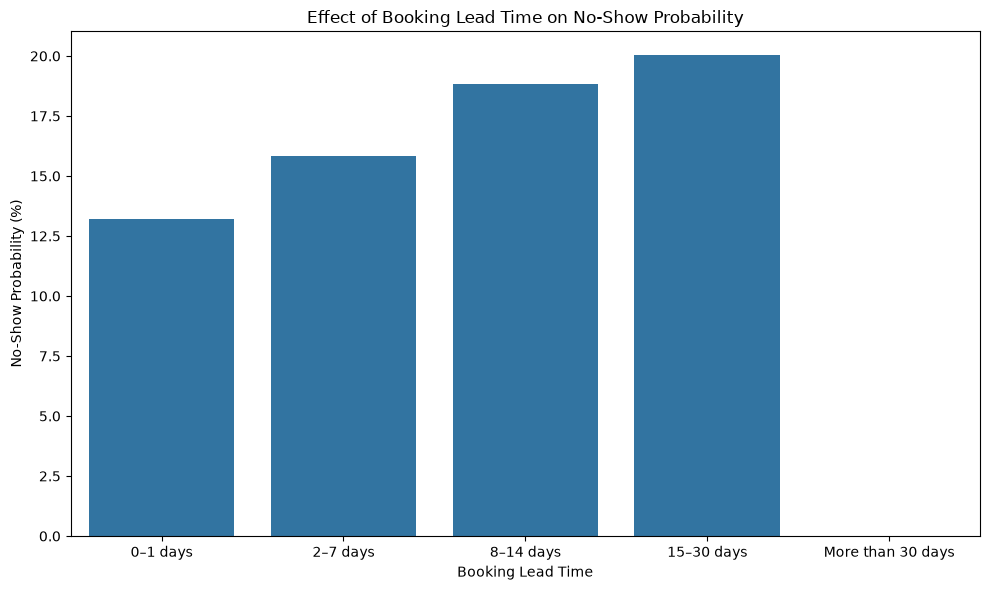

In [84]:

plt.figure(figsize=(10, 6))

sns.barplot(
    data=lead_time_summary.reset_index(),
    x="Lead_Time_Group",
    y="No_Show_Probability"
)

plt.title("Effect of Booking Lead Time on No-Show Probability")
plt.xlabel("Booking Lead Time")
plt.ylabel("No-Show Probability (%)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


### 📌 Insight
- No-show probability **rises with booking lead time**: 13.2% (0–1 days) → 15.8% (2–7) → 18.8% (8–14) → 20.0% (15–30).
- The "More than 30 days" group has **no eligible appointments**, so it is empty.

## 3. Do evening slots, weekends, and longer-lead bookings see higher dropout? 

In [85]:
# Create a weekend/weekday column
eligible_appointments["Day_Type"] = eligible_appointments[
    "appointment_day"
].apply(
    lambda day: "Weekend" if day in ["Saturday", "Sunday"] else "Weekday"
)

# Create a reusable summary function
def no_show_summary(data, group_column):
    summary = data.groupby(group_column, observed=False).agg(
        Total_Eligible=("no_show_flag", "count"),
        Total_No_Shows=("no_show_flag", "sum")
    )

    summary["No_Show_Rate"] = (
        summary["Total_No_Shows"] / summary["Total_Eligible"]
    ) * 100

    return summary

# Calculate the three summaries
time_summary = no_show_summary(
    eligible_appointments, "time_of_day"
)

day_summary = no_show_summary(
    eligible_appointments, "Day_Type"
)

lead_summary = no_show_summary(
    eligible_appointments, "Lead_Time_Group"
)

# Display the results
print("No-show rate by time of day:")
display(time_summary)

print("No-show rate on weekdays vs weekends:")
display(day_summary)

print("No-show rate by booking lead time:")
display(lead_summary)


No-show rate by time of day:


,Total_Eligible,Total_No_Shows,No_Show_Rate
time_of_day,,,
Afternoon,23231,4124,17.752142
Evening,14553,2673,18.367347
Morning,34868,4787,13.728921


No-show rate on weekdays vs weekends:


,Total_Eligible,Total_No_Shows,No_Show_Rate
Day_Type,,,
Weekday,51731,7676,14.838298
Weekend,20921,3908,18.679795


No-show rate by booking lead time:


,Total_Eligible,Total_No_Shows,No_Show_Rate
Lead_Time_Group,,,
0–1 days,10453,1382,13.221085
2–7 days,30919,4892,15.821986
8–14 days,8758,1648,18.817082
15–30 days,2342,469,20.025619
More than 30 days,0,0,NaN


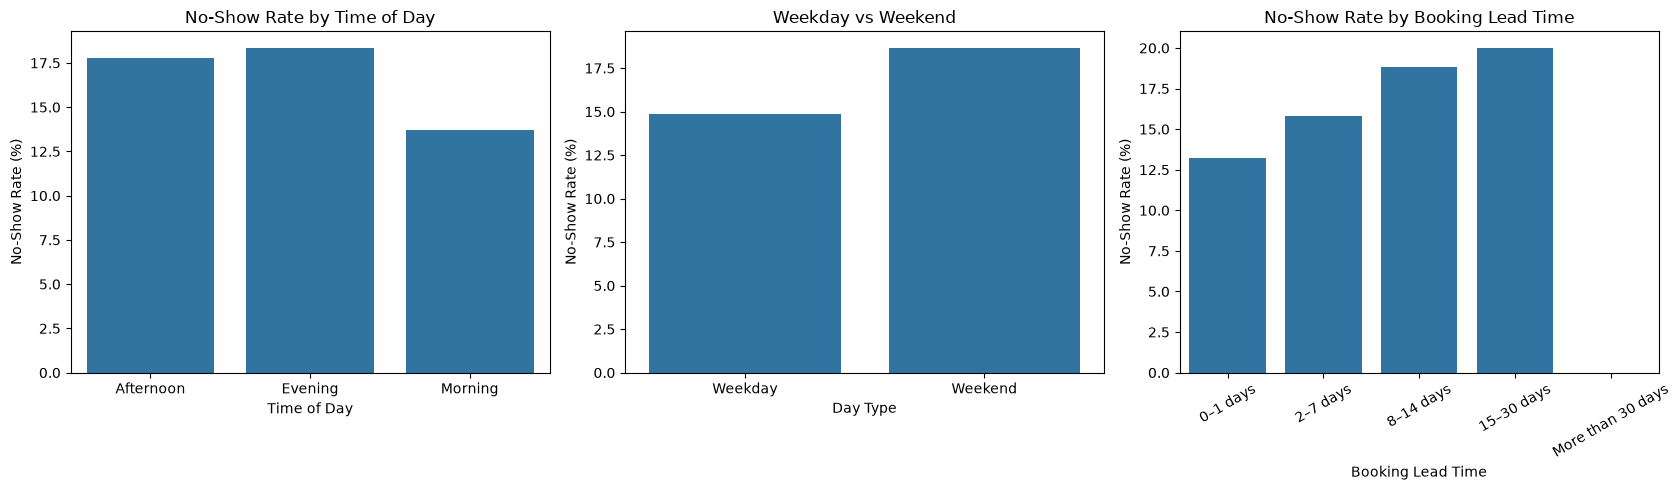

In [86]:

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

sns.barplot(
    data=time_summary.reset_index(),
    x="time_of_day",
    y="No_Show_Rate",
    ax=axes[0]
)
axes[0].set_title("No-Show Rate by Time of Day")
axes[0].set_xlabel("Time of Day")
axes[0].set_ylabel("No-Show Rate (%)")

sns.barplot(
    data=day_summary.reset_index(),
    x="Day_Type",
    y="No_Show_Rate",
    ax=axes[1]
)
axes[1].set_title("Weekday vs Weekend")
axes[1].set_xlabel("Day Type")
axes[1].set_ylabel("No-Show Rate (%)")

sns.barplot(
    data=lead_summary.reset_index(),
    x="Lead_Time_Group",
    y="No_Show_Rate",
    ax=axes[2]
)
axes[2].set_title("No-Show Rate by Booking Lead Time")
axes[2].set_xlabel("Booking Lead Time")
axes[2].set_ylabel("No-Show Rate (%)")
axes[2].tick_params(axis="x", rotation=30)

plt.tight_layout()
plt.show()


### 📌 Insight
- **Evening (18.4%)** and **afternoon (17.8%)** slots have more no-shows than **morning (13.7%)**.
- **Weekends (18.7%)** are higher than weekdays (14.8%).

## 4. Which appointment types and booking channels carry the most no-show risk? 

In [41]:
# Appointment type data summary 

AppointmentType_Summary=eligible_appointments.pivot_table(
    index=["appointment_type"],
    values=["no_show_flag"],
    aggfunc=["count","sum"]
)
AppointmentType_Summary.columns=["Total_type","Total_noshows"]
AppointmentType_Summary["no_showRate"]=(AppointmentType_Summary["Total_noshows"]/AppointmentType_Summary["Total_type"])*100
AppointmentType_Summary=AppointmentType_Summary.sort_values("no_showRate",ascending = False )

AppointmentType_Summary

# booking chanel summary 
Booking_Chanel_Summary=eligible_appointments.pivot_table(
    index=["booking_channel"],
    values=["no_show_flag"],
    aggfunc=["count","sum"]
)

Booking_Chanel_Summary.columns=["Total_channel","Total_noshows"]
Booking_Chanel_Summary["no_showRate"]=(Booking_Chanel_Summary["Total_noshows"]/Booking_Chanel_Summary["Total_channel"])*100
Booking_Chanel_Summary=Booking_Chanel_Summary.sort_values("no_showRate",ascending = False)

Booking_Chanel_Summary

,Total_channel,Total_noshows,no_showRate
booking_channel,,,
Walk-In,7281,1520,20.876253
Partner App,3594,651,18.113523
Website,17964,3090,17.201069
Call Centre,10855,1650,15.200368
Apollo App,32958,4673,14.178652


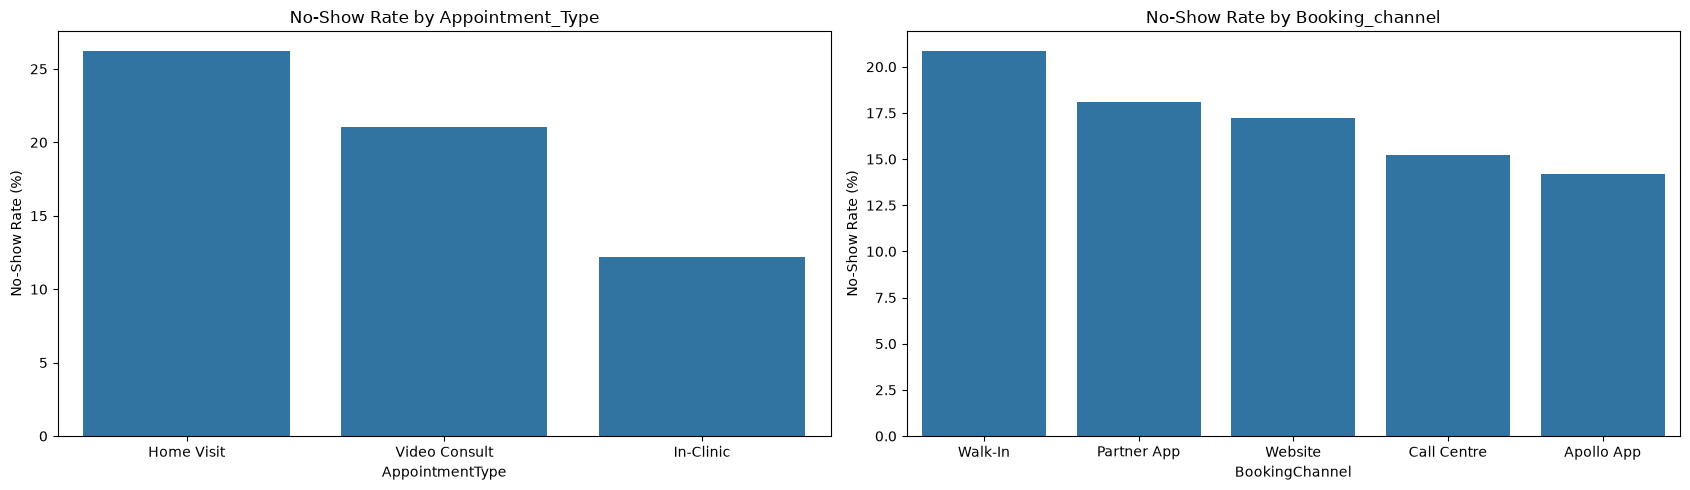

In [42]:
# Visualizations 
fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.barplot(
    data=AppointmentType_Summary,
    x="appointment_type",
    y="no_showRate",
    ax=axes[0]
)
axes[0].set_title("No-Show Rate by Appointment_Type")
axes[0].set_xlabel("AppointmentType")
axes[0].set_ylabel("No-Show Rate (%)")

sns.barplot(
    data=Booking_Chanel_Summary,
    x="booking_channel",
    y="no_showRate",
    ax=axes[1]
)
axes[1].set_title("No-Show Rate by Booking_channel")
axes[1].set_xlabel("BookingChannel")
axes[1].set_ylabel("No-Show Rate (%)")

plt.tight_layout()
plt.show()



### 📌 Insight
- **Home Visit (about 26%)** and **Video Consult (about 21%)** carry far more risk than **In-Clinic (about 12%)**.
- **Walk-In (20.9%)** and **Partner App (18.1%)** are the riskiest channels; **Apollo App (14.2%)** is the safest.

## Reminder and Engagement Effectiveness 

## 1.How much does reminder type reduce no-show rates compared to no-reminder patients? 

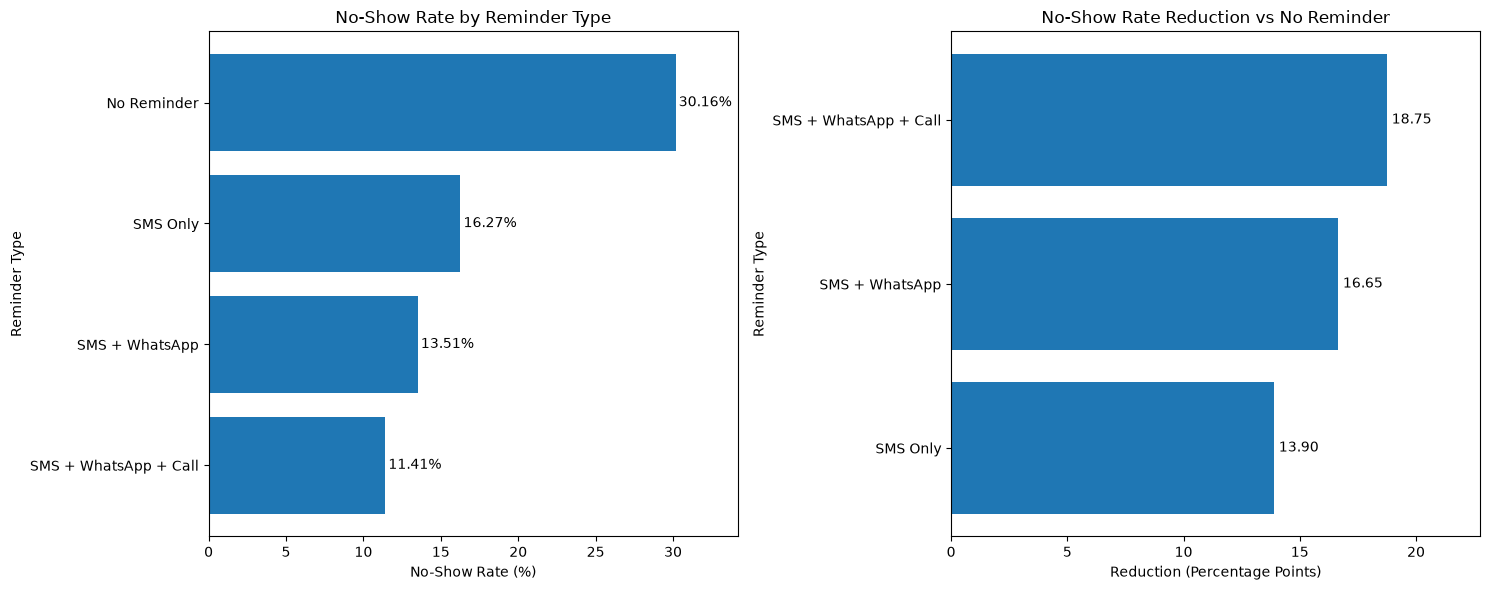

In [87]:

reminder_summary = eligible_appointments.pivot_table(
    index="reminder_type",
    values="no_show_flag",
    aggfunc=["count","sum"]
)
reminder_summary.columns = ["Total_eligible", "Total_no_shows"]

reminder_summary["No_show_rate"] = (
    reminder_summary["Total_no_shows"]
    / reminder_summary["Total_eligible"]
) * 100

reminder_summary = reminder_summary.sort_values(
    by="No_show_rate",
    ascending=False
)

no_reminder_rate = reminder_summary.loc[
    "No Reminder", "No_show_rate"
]

reminder_rates = reminder_summary.drop(index="No Reminder")

reminder_rates["Reduction_percentage_points"] = (
    no_reminder_rate - reminder_rates["No_show_rate"]
)

reminder_rates["Relative_reduction_percent"] = (
    reminder_rates["Reduction_percentage_points"]
    / no_reminder_rate
) * 100

reminder_rates
# Create two side-by-side charts
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Chart 1: No-show rate by reminder type
plot_data = reminder_summary.sort_values(
    by="No_show_rate",
    ascending=True
)

bars1 = axes[0].barh(
    plot_data.index,
    plot_data["No_show_rate"]
)

axes[0].set_title("No-Show Rate by Reminder Type")
axes[0].set_xlabel("No-Show Rate (%)")
axes[0].set_ylabel("Reminder Type")

for bar in bars1:
    width = bar.get_width()
    axes[0].text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}%",
        va="center"
    )

axes[0].set_xlim(0, plot_data["No_show_rate"].max() + 4)

# Chart 2: Reduction compared with no-reminder patients
reduction_data = reminder_rates.sort_values(
    by="Reduction_percentage_points",
    ascending=True
)

bars2 = axes[1].barh(
    reduction_data.index,
    reduction_data["Reduction_percentage_points"]
)

axes[1].set_title("No-Show Rate Reduction vs No Reminder")
axes[1].set_xlabel("Reduction (Percentage Points)")
axes[1].set_ylabel("Reminder Type")

for bar in bars2:
    width = bar.get_width()
    axes[1].text(
        width + 0.2,
        bar.get_y() + bar.get_height() / 2,
        f"{width:.2f}",
        va="center"
    )

axes[1].set_xlim(
    0,
    reduction_data["Reduction_percentage_points"].max() + 4
)

plt.tight_layout()
plt.show()



### 📌 Insight
Reminders are the strongest lever in this analysis.

| Reminder type | No-show rate | Reduction vs no reminder |
|---|---|---|
| No reminder | 30.16% | – |
| SMS only | 16.27% | −13.90 pp (about 46% lower) |
| SMS + WhatsApp | 13.51% | −16.65 pp (about 55% lower) |
| SMS + WhatsApp + Call | 11.41% | −18.75 pp (about 62% lower) |

## 2. Does prior no-show history predict future no-show behaviour? 

                     Total_Eligible  Total_No_Shows  No_Show_Rate
Previous_No_Show                                                 
No Previous No-Show           35954            5626     15.647772
Previous No-Show               4350             898     20.643678


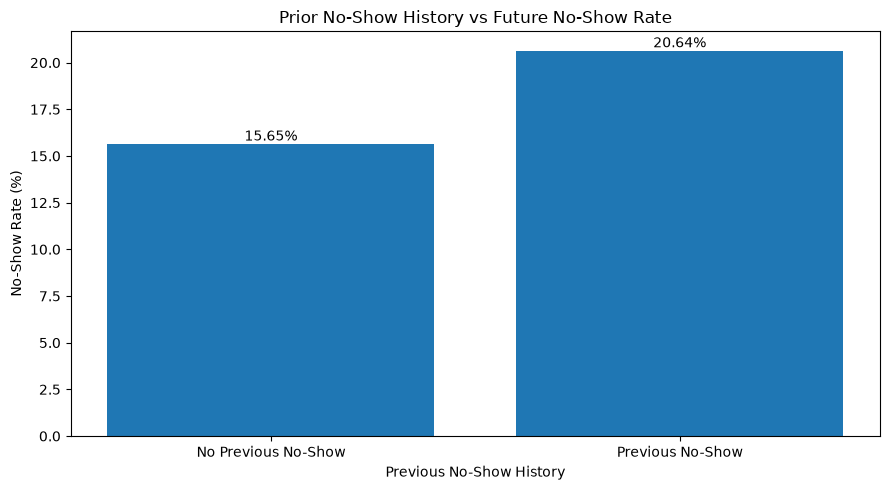

In [89]:
Appointment_data.columns.tolist()

# 1. Set the actual column names from your dataset
patient_col = "patient_id"       # Change if needed
date_col = "appointment_date"    # Change if needed

# 2. Copy data and convert appointment date to datetime
history_data = Appointment_data.copy()

history_data[date_col] = pd.to_datetime(
    history_data[date_col],
    errors="coerce"
)

# 3. Keep eligible appointments only
history_data = history_data[
    history_data["appointment_status"].isin(
        ["Completed", "No-Show", "Cancelled"]
    )
].copy()

# Remove rows missing patient ID or appointment date
history_data = history_data.dropna(
    subset=[patient_col, date_col]
)

# 4. Sort appointments by patient and date
history_data = history_data.sort_values(
    by=[patient_col, date_col]
).copy()

# 5. Identify previous no-show history
history_data["Previous_No_Show"] = (
    history_data.groupby(patient_col)["no_show_flag"]
    .transform(lambda s: s.shift(1).eq(1).cummax().shift(fill_value=False))
)

# 6. Exclude first appointments because prior history is unknown
# Keep appointments only when an earlier eligible appointment exists
history_data["Previous_Appointment_Count"] = (
    history_data.groupby(patient_col).cumcount()
)

analysis_data = history_data[
    history_data["Previous_Appointment_Count"] > 0
].copy()

# 7. Summarize no-show rates by previous history
history_summary = analysis_data.groupby(
    "Previous_No_Show"
).agg(
    Total_Eligible=("no_show_flag", "count"),
    Total_No_Shows=("no_show_flag", "sum")
)

history_summary["No_Show_Rate"] = (
    history_summary["Total_No_Shows"]
    / history_summary["Total_Eligible"]
) * 100

history_summary.index = history_summary.index.map({
    False: "No Previous No-Show",
    True: "Previous No-Show"
})

print(history_summary)

# 8. Visualize the comparison
plt.figure(figsize=(9, 5))

bars = plt.bar(
    history_summary.index,
    history_summary["No_Show_Rate"]
)

plt.title("Prior No-Show History vs Future No-Show Rate")
plt.xlabel("Previous No-Show History")
plt.ylabel("No-Show Rate (%)")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{height:.2f}%",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()



### 📌 Insight
- Patients with a **previous no-show** miss again **20.6%** of the time, versus **15.6%** for patients with no earlier no-show (about 5 percentage points higher).

## 3. Do Apollo members and repeat patients show better attendance than non-members and first-time patients? 

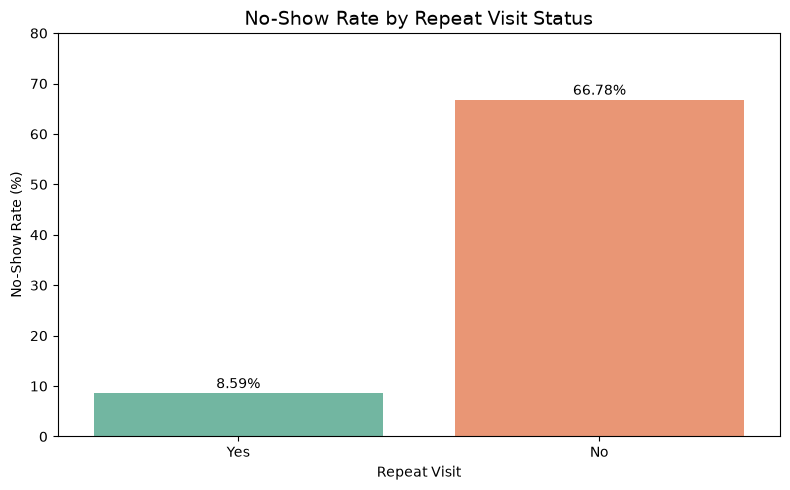

In [90]:

membership_pivot = eligible_appointments.pivot_table(
    index="membership_type",
    values="no_show_flag",
    aggfunc=["count", "sum"],
    dropna=False
)

membership_pivot.columns = ["Total_Eligible", "Total_No_Shows"]

membership_pivot["No_Show_Rate (%)"] = (
    membership_pivot["Total_No_Shows"]
    / membership_pivot["Total_Eligible"] * 100
).round(2)

membership_pivot = membership_pivot.sort_values(
    by="No_Show_Rate (%)",
    ascending=True
)

membership_pivot
repeat_pivot = eligible_appointments.pivot_table(
    index="repeat_visit",
    values="no_show_flag",
    aggfunc=["count", "sum"],
    dropna=False
)

repeat_pivot.columns = ["Total_Eligible", "Total_No_Shows"]

repeat_pivot["No_Show_Rate (%)"] = (
    repeat_pivot["Total_No_Shows"]
    / repeat_pivot["Total_Eligible"] * 100
).round(2)

repeat_pivot = repeat_pivot.sort_values(
    by="No_Show_Rate (%)",
    ascending=True
)

repeat_pivot
# Create the bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=repeat_pivot.index,
    y=repeat_pivot["No_Show_Rate (%)"],
    hue=repeat_pivot.index,
    palette="Set2",
    legend=False
)

# Add labels and title
plt.title("No-Show Rate by Repeat Visit Status", fontsize=14)
plt.xlabel("Repeat Visit")
plt.ylabel("No-Show Rate (%)")

# Display percentage values on top of bars
for i, value in enumerate(repeat_pivot["No_Show_Rate (%)"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.ylim(0, 80)
plt.tight_layout()
plt.show()

### 📌 Insight
- **Repeat patients** have a no-show rate of **8.6%**, while **first-time patients** have **66.8%**.
- This gap is very large, so check how `repeat_visit` is defined before drawing strong conclusions.

## Patient and Demographic Segmentation

## 1. How do age group, gender, and chronic condition status influence no-show likelihood? 

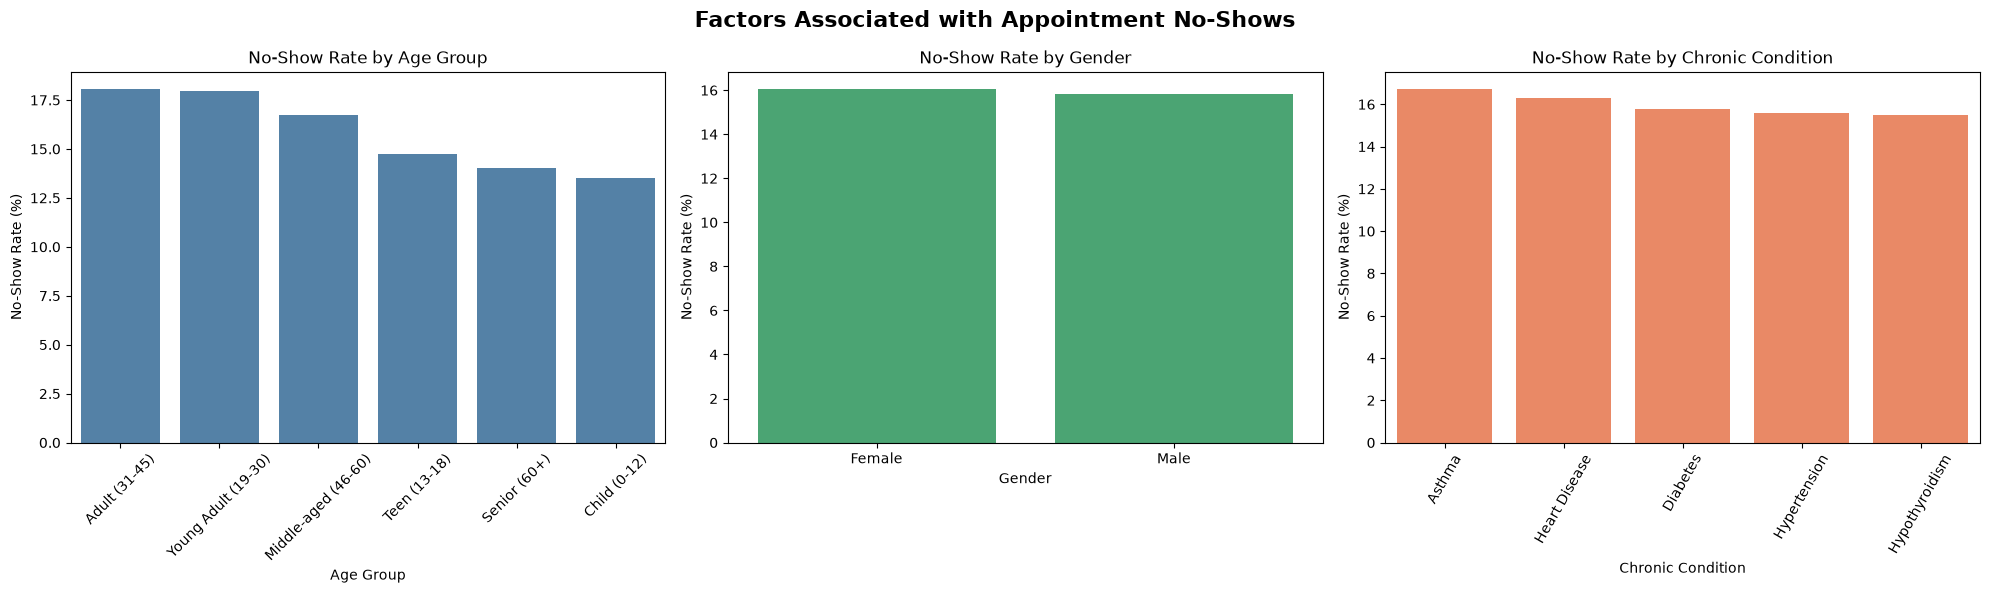

In [92]:

Appointment_data["chronic_condition_status"] = (
    Appointment_data["patient_chronic_condition"]
    .notna()
    .map({
        True: "Condition Recorded",
        False: "Condition Not Recorded"
    })
)
Appointment_data["chronic_condition_status"]

# age summary 
Age_summary=eligible_appointments.pivot_table(
    index="age_group",
    values="no_show_flag",
    aggfunc=["count","sum"]
)
Age_summary.columns=["Total_type","Total_noshows"]
Age_summary["No_Show_Rate"]=(Age_summary["Total_noshows"]/Age_summary["Total_type"])*100
Age_summary=Age_summary.sort_values("No_Show_Rate",ascending = False )
Age_summary

# gender Summary 
Gender_summary = eligible_appointments.pivot_table(
    index="patient_gender",
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

Gender_summary.columns = ["Total_Eligible", "Total_No_Shows"]

Gender_summary["No_Show_Rate (%)"] = (
    Gender_summary["Total_No_Shows"]
    / Gender_summary["Total_Eligible"]
) * 100

Gender_summary = Gender_summary.sort_values(
    "No_Show_Rate (%)",
    ascending=False
)

Gender_summary

# chronic condition status Summary 
 
Chronic_summary = eligible_appointments.pivot_table(
    index="patient_chronic_condition",
    values="no_show_flag",
    aggfunc=["count", "sum"],
    dropna=False
)

Chronic_summary.columns = ["Total_Eligible", "Total_No_Shows"]

Chronic_summary["No_Show_Rate (%)"] = (
    Chronic_summary["Total_No_Shows"]
    / Chronic_summary["Total_Eligible"]
) * 100

Chronic_summary = Chronic_summary.sort_values(
    "No_Show_Rate (%)",
    ascending=False
)

Chronic_summary

# Visualizations 

# Create three subplots
fig, axes = plt.subplots(1, 3, figsize=(20, 6))

# 1. Age Group vs No-Show Rate
age_plot = Age_summary.sort_values(
    "No_Show_Rate", ascending=False
)

sns.barplot(
    x=age_plot.index.astype(str),
    y=age_plot["No_Show_Rate"],
    ax=axes[0],
    color="steelblue"
)

axes[0].set_title("No-Show Rate by Age Group")
axes[0].set_xlabel("Age Group")
axes[0].set_ylabel("No-Show Rate (%)")
axes[0].tick_params(axis="x", rotation=45)



# 2. Gender vs No-Show Rate
gender_plot = Gender_summary.sort_values(
    "No_Show_Rate (%)", ascending=False
)

sns.barplot(
    x=gender_plot.index.astype(str),
    y=gender_plot["No_Show_Rate (%)"],
    ax=axes[1],
    color="mediumseagreen"
)

axes[1].set_title("No-Show Rate by Gender")
axes[1].set_xlabel("Gender")
axes[1].set_ylabel("No-Show Rate (%)")

# 3. Chronic Condition vs No-Show Rate
chronic_plot = Chronic_summary.sort_values(
    "No_Show_Rate (%)", ascending=False
)

sns.barplot(
    x=chronic_plot.index.astype(str),
    y=chronic_plot["No_Show_Rate (%)"],
    ax=axes[2],
    color="coral"
)

axes[2].set_title("No-Show Rate by Chronic Condition")
axes[2].set_xlabel("Chronic Condition")
axes[2].set_ylabel("No-Show Rate (%)")
axes[2].tick_params(axis="x", rotation=60)

# Main title and layout
fig.suptitle(
    "Factors Associated with Appointment No-Shows",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()




### 📌 Insight
- Adults aged **19–45** have the highest no-show rate (about 18%); **children (0–12)** and **seniors (60+)** are lowest (about 13.5% and 14%).
- **Gender** (about 16% for both) and **chronic condition** (about 15.5%–16.7%) show little difference.

## 2. Which visit reasons are most common and are some associated with higher dropout? 

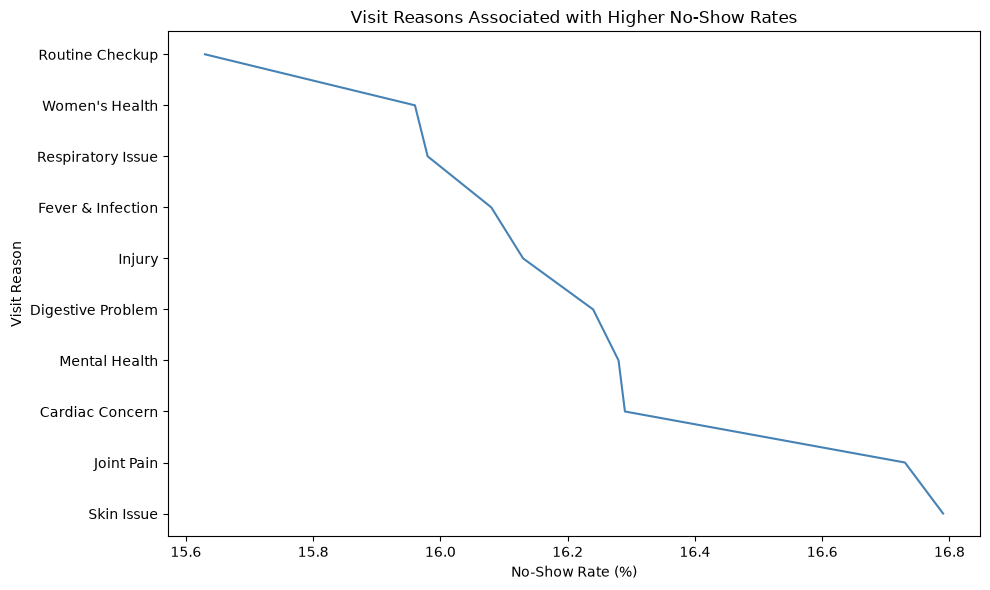

In [93]:

visit_reason_summary = eligible_appointments.pivot_table(
    index="visit_reason",
    values="no_show_flag",
    aggfunc=["count", "sum"]
)

visit_reason_summary.columns = [
    "Total_Eligible",
    "Total_No_Shows"
]

visit_reason_summary["No_Show_Rate (%)"] = (
    visit_reason_summary["Total_No_Shows"]
    / visit_reason_summary["Total_Eligible"] * 100
).round(2)

visit_reason_summary = visit_reason_summary.sort_values(
    by="No_Show_Rate (%)",
    ascending=False
)

visit_reason_summary

reliable_reasons = visit_reason_summary[
    visit_reason_summary["Total_Eligible"] >= 100
].sort_values(
    by="No_Show_Rate (%)",
    ascending=False
)

reliable_reasons.head(5)

# Visualizations 

plot_data = reliable_reasons.head(10).sort_values(
    "No_Show_Rate (%)",
    ascending=True
)

plt.figure(figsize=(10, 6))

sns.lineplot(
    data=plot_data,
    x="No_Show_Rate (%)",
    y=plot_data.index.astype(str),
    color="steelblue"
)

plt.title("Visit Reasons Associated with Higher No-Show Rates")
plt.xlabel("No-Show Rate (%)")
plt.ylabel("Visit Reason")
plt.tight_layout()
plt.show()


### 📌 Insight
- All top visit reasons fall in a narrow band of about **15.6%–16.8%**, with **Skin Issue** the highest. Visit reason is not a strong separator of no-show risk.

## 3. What does the patient age distribution look like within specialties like Paediatrics, Gynaecology, and Psychiatry? 

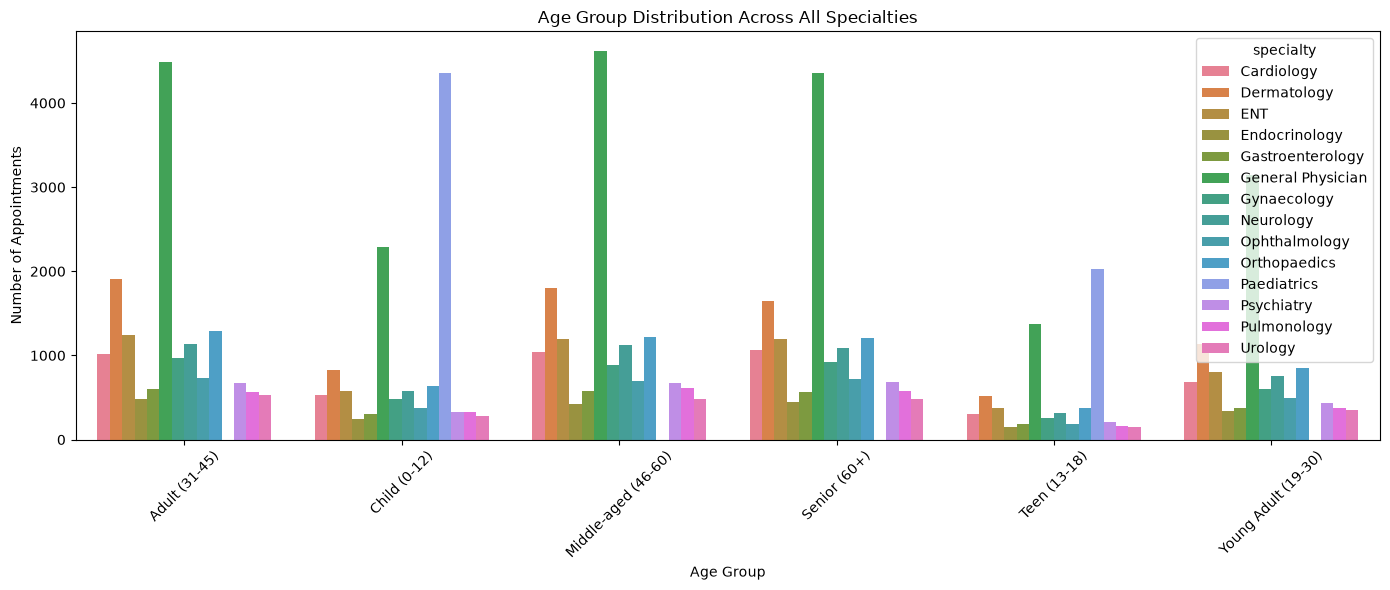

In [14]:

age_specialty_summary = Appointment_data.pivot_table(
    index="age_group",
    columns="specialty",
    aggfunc="size",
    fill_value=0
)

age_specialty_summary 

# ViSulizations 
plot_data = age_specialty_summary.reset_index().melt(
    id_vars="age_group",
    var_name="specialty",
    value_name="appointments"
)

plt.figure(figsize=(14, 6))
sns.barplot(data=plot_data, x="age_group", y="appointments", hue="specialty")

plt.title("Age Group Distribution Across All Specialties")
plt.xlabel("Age Group")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## Financial Performance

## 1. How much revenue is being lost to no-shows? 

Total No-Shows: 11584
Estimated Potential Revenue Loss: 15485947.64


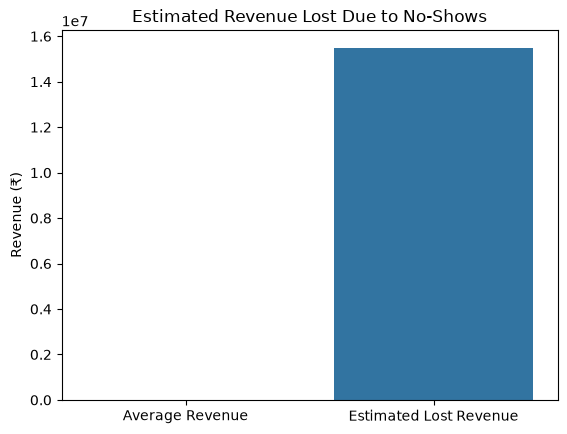

In [54]:
# Average revenue per completed appointment
avg_revenue = Appointment_data.loc[
    Appointment_data["appointment_status"] == "Completed",
    "revenue_realized"
].mean()

# Total no-show appointments
total_no_shows = (Appointment_data["no_show"] == "Yes").sum()

# Estimated potential revenue loss
lost_revenue = avg_revenue * total_no_shows

print("Total No-Shows:", total_no_shows)
print("Estimated Potential Revenue Loss:", round(lost_revenue, 2))
 # Visualizations 
sns.barplot(
    x=["Average Revenue", "Estimated Lost Revenue"],
    y=[avg_revenue, lost_revenue]
)

plt.title("Estimated Revenue Lost Due to No-Shows")
plt.ylabel("Revenue (₹)")
plt.xlabel("")

plt.show()

### 📌 Insight
- Average revenue per completed appointment is about **₹1,337**.
- Estimated revenue lost to **11,584 no-shows** is about **₹1.55 crore (₹15,485,948)**. This is an estimate: average completed revenue × number of no-shows.

## 2. How does average revenue vary across specialties and appointment types? 

In [6]:
# Specialties_revenue
Specialties_revenue=Appointment_data.pivot_table(
    index="specialty",
    values="revenue_realized",
    aggfunc="mean"
)
Specialties_revenue.columns=["avg_revenue"]
Specialties_revenue


# Appointment_type _revenue 
Appointment_type_revenue=Appointment_data.pivot_table(
    index="appointment_type",
    values="revenue_realized",
    aggfunc="mean"
)
Appointment_type_revenue.columns=["avg_revenue"]

# Visualizations  for Speciality 
plt.figure(figsize=(25, 10))

sns.lineplot(
    data=Specialties_revenue,
    x="specialty",
    y="avg_revenue",
    marker="o"
)

plt.title("Average Revenue by Specialty", fontsize=18, fontweight="bold")
plt.xlabel("Specialty", fontsize=20, fontweight="bold")
plt.ylabel("Average Revenue (₹)", fontsize=15, fontweight="bold")

# X-axis labels bold and larger
plt.xticks(rotation=45, fontsize=20, fontweight="bold")
plt.yticks(fontsize=20)

plt.tight_layout()
plt.show()


NameError: name 'Appointment_data' is not defined

In [5]:
# Visualization for Appointment Type 

plt.figure(figsize=(25, 10))

sns.lineplot(
    data=Appointment_type_revenue,
    x="appointment_type",
    y="avg_revenue",
    marker="o"
)

plt.title("Average Revenue by Appointment Type", fontsize=18, fontweight="bold")
plt.xlabel("Appointment Type", fontsize=15, fontweight="bold")
plt.ylabel("Average Revenue (₹)", fontsize=15, fontweight="bold")

plt.xticks(rotation=90, fontsize=20, fontweight="bold")
plt.yticks(fontsize=20)

plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

## 3. Which cities generate the most revenue and what is the payment mode mix? 

In [57]:
# City-wise revenue
City_revenue = Appointment_data.groupby("city", as_index=False).agg(
    total_revenue=("revenue_realized", "sum")
)

City_revenue = City_revenue.sort_values(
    "total_revenue", ascending=False
)

City_revenue


,city,total_revenue
1,Bengaluru,9990616
6,Delhi,9958247
13,Mumbai,8989613
7,Hyderabad,7503245
4,Chennai,7188473
11,Kolkata,6543084
14,Pune,4734139
0,Ahmedabad,3956890
12,Lucknow,3177444
8,Indore,2223207


In [1]:
# Visualizations 
plt.figure(figsize=(12, 6))

sns.barplot(data=City_revenue, x="city", y="total_revenue")

plt.title("Total Revenue by City")
plt.xlabel("City")
plt.ylabel("Total Revenue (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

NameError: name 'plt' is not defined

### 📌 Insight
- **Bengaluru (₹99.9 lakh)**, **Delhi (₹99.6 lakh)** and **Mumbai (₹89.9 lakh)** lead, together about **39%** of total revenue (₹7.39 crore).
- Bhopal (₹16.8 lakh) and Kochi (₹17.3 lakh) are the lowest.

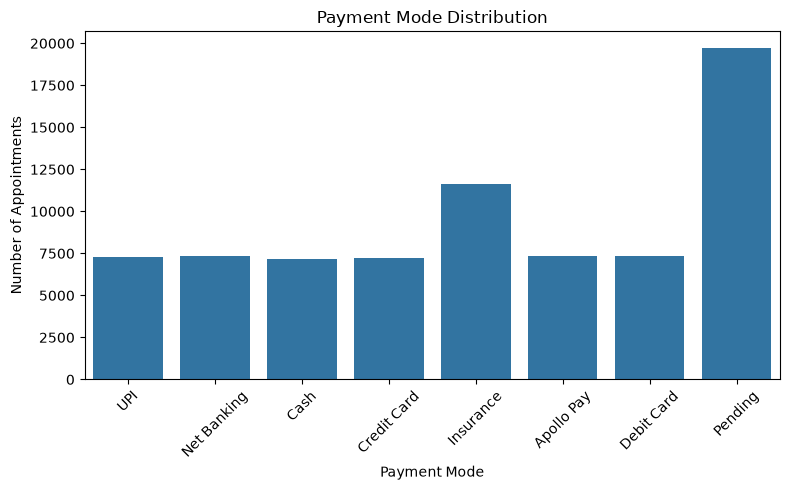

In [59]:
#Payment mode mix
Appointment_data["payment_mode"].value_counts()
plt.figure(figsize=(8, 5))

sns.countplot(data=Appointment_data, x="payment_mode")

plt.title("Payment Mode Distribution")
plt.xlabel("Payment Mode")
plt.ylabel("Number of Appointments")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

## 4. How does insurance coverage affect what patients pay out of pocket? 

In [60]:
Insurance_summary = Appointment_data.groupby(
    "insurance_coverage", as_index=False
).agg(
    total_patients=("patient_out_of_pocket", "count"),
    avg_out_of_pocket=("patient_out_of_pocket", "mean")
)

Insurance_summary


,insurance_coverage,total_patients,avg_out_of_pocket
0,No,51512,1138.408914
1,Yes,23488,649.356182


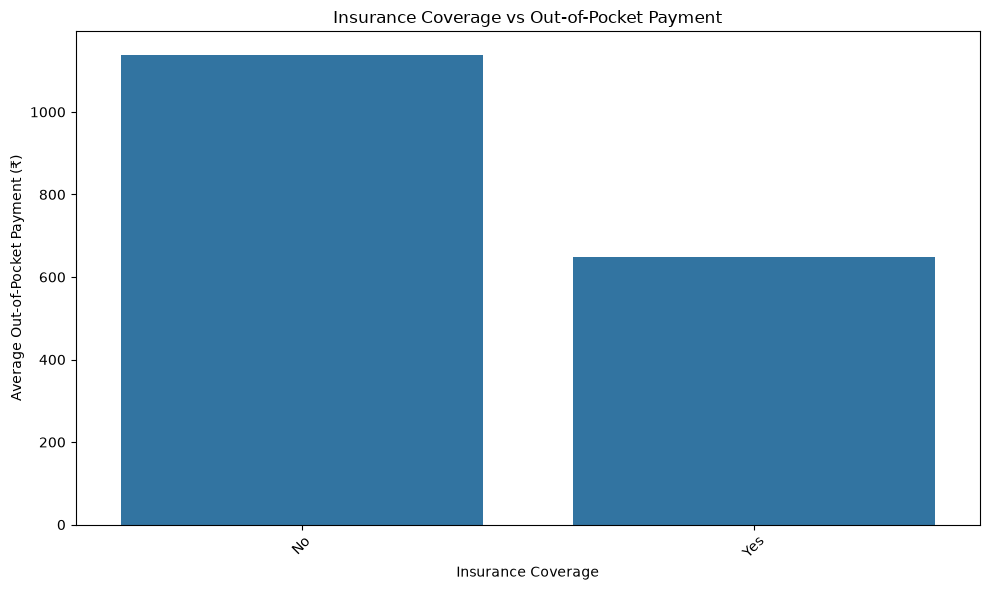

In [61]:
plt.figure(figsize=(10, 6))

sns.barplot(
    data=Insurance_summary,
    x="insurance_coverage",
    y="avg_out_of_pocket",
    errorbar=None
)

plt.title("Insurance Coverage vs Out-of-Pocket Payment")
plt.xlabel("Insurance Coverage")
plt.ylabel("Average Out-of-Pocket Payment (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


### 📌 Insight
- Patients **with insurance** pay about **₹649** out of pocket on average versus **₹1,138** without, roughly **43% less**.

## Doctor Utilisation and Service Quality 

## 1. Which specialties have the highest and lowest doctor utilisation rates? 

In [62]:
doctor_usage = Appointment_data.groupby(
    "doctor_id"
).size().reset_index(name="total_appointments")

# Add doctor specialty
doctor_usage = doctor_usage.merge(
    Apollo_doctor[["doctor_id", "specialty"]],
    on="doctor_id",
    how="left"
)

# Calculate specialty-wise appointments
Specialty_usage = doctor_usage.groupby(
    "specialty", as_index=False
)["total_appointments"].sum()

Specialty_usage = Specialty_usage.sort_values(
    "total_appointments", ascending=False
)

Specialty_usage

,specialty,total_appointments
5,General Physician,20272
1,Dermatology,7824
10,Paediatrics,6382
9,Orthopaedics,5589
2,ENT,5385
7,Neurology,4993
0,Cardiology,4641
6,Gynaecology,4113
8,Ophthalmology,3193
11,Psychiatry,2989


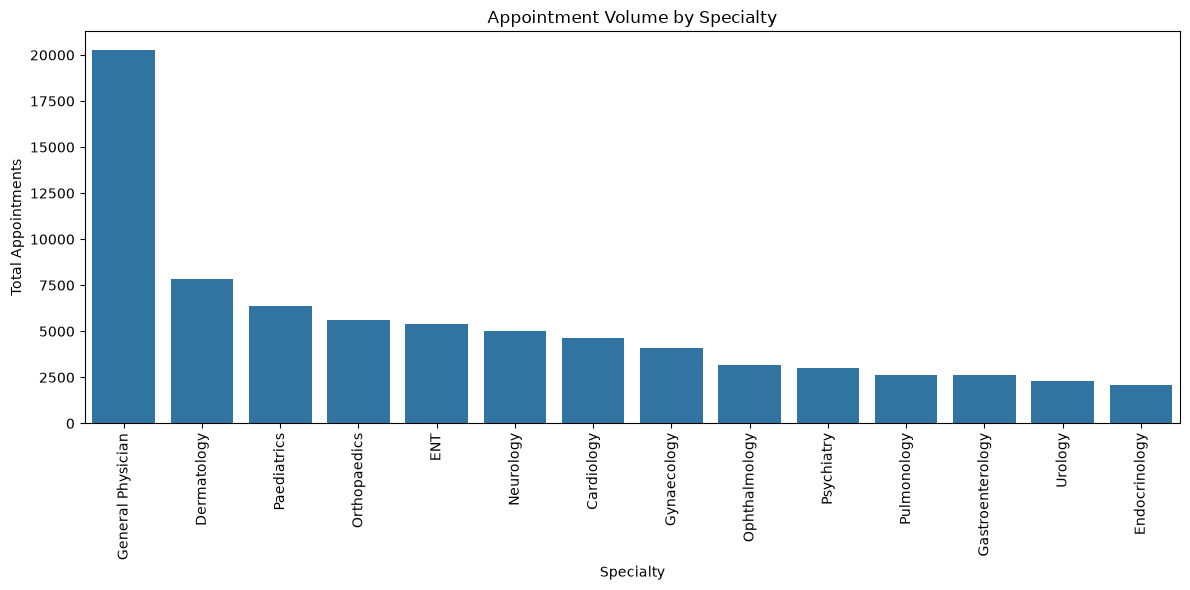

In [63]:
# Visualizations 
plt.figure(figsize=(12, 6))

sns.barplot(
    data=Specialty_usage,
    x="specialty",
    y="total_appointments"
)

plt.title("Appointment Volume by Specialty")
plt.xlabel("Specialty")
plt.ylabel("Total Appointments")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

### 📌 Insight
- **General Physician** handles the most appointments (**20,272**, about 27% of the total), then Dermatology (7,824) and Paediatrics (6,382).
- **Endocrinology** is the lowest (2,087).

## 2. How long are patients waiting and does it vary by specialty or time of day? 

In [15]:

Waiting_summary = Appointment_data.groupby(
    ["specialty", "time_of_day"],
    as_index=False
).agg(
    avg_wait_time=("wait_time_minutes", "mean")
)

Waiting_summary["avg_wait_time"] = (
    Waiting_summary["avg_wait_time"].round(2)
)

Waiting_summary


,specialty,time_of_day,avg_wait_time
0,Cardiology,Afternoon,11.88
1,Cardiology,Evening,11.37
2,Cardiology,Morning,11.50
3,Dermatology,Afternoon,11.68
4,Dermatology,Evening,10.77
5,Dermatology,Morning,12.23
6,ENT,Afternoon,11.56
7,ENT,Evening,11.33
8,ENT,Morning,11.11
9,Endocrinology,Afternoon,11.10


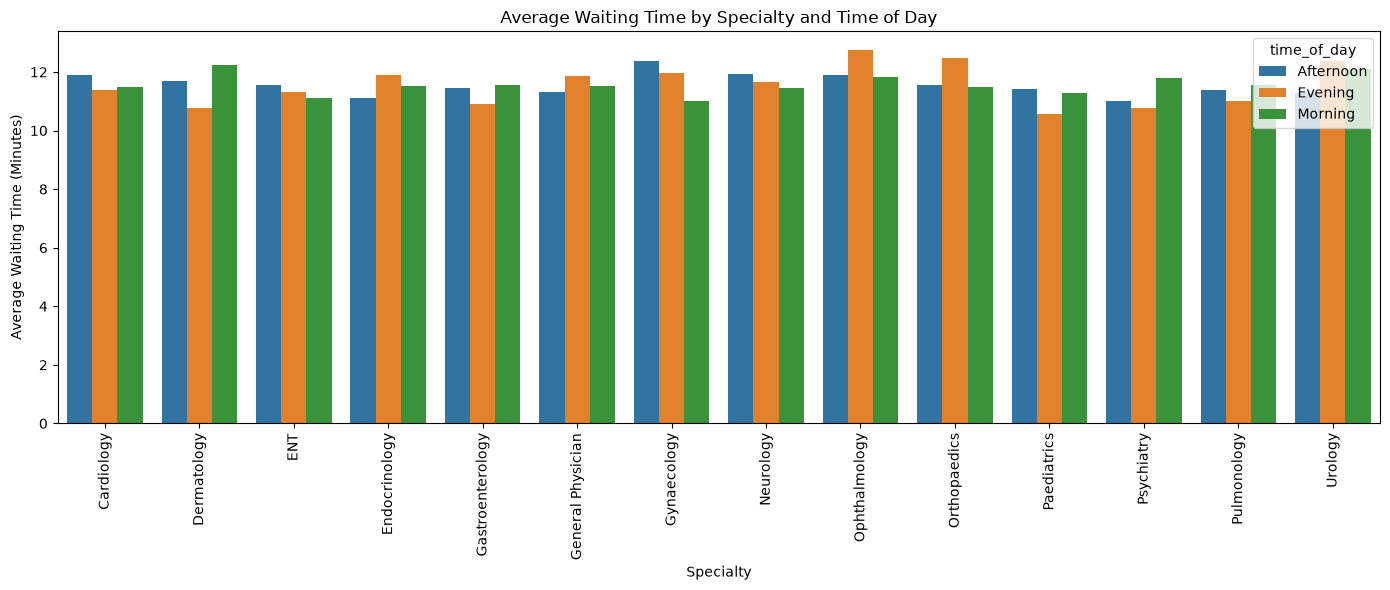

In [65]:
# Visualizations 

plt.figure(figsize=(14, 6))

sns.barplot(
    data=Waiting_summary,
    x="specialty",
    y="avg_wait_time",
    hue="time_of_day",
    errorbar=None
)

plt.title("Average Waiting Time by Specialty and Time of Day")
plt.xlabel("Specialty")
plt.ylabel("Average Waiting Time (Minutes)")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


### 📌 Insight
- Average waiting time is **similar everywhere, about 11–12.5 minutes**, across specialties and times of day.

## 3. Is there a relationship between consultation duration and patient satisfaction? 

In [66]:

Duration_summary = Appointment_data[
    ["consultation_duration_min", "patient_satisfaction_score"]
].dropna()

print(
    Duration_summary.corr().round(2)
)



                            consultation_duration_min  \
consultation_duration_min                         1.0   
patient_satisfaction_score                       -0.0   

                            patient_satisfaction_score  
consultation_duration_min                         -0.0  
patient_satisfaction_score                         1.0  


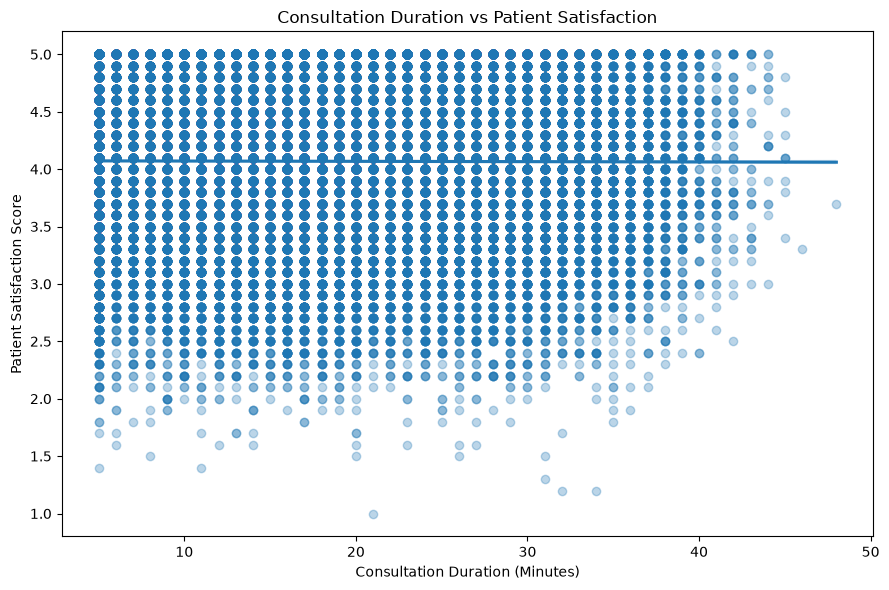

In [67]:
# Visualizations 

plt.figure(figsize=(9, 6))

sns.regplot(
    data=Duration_summary,
    x="consultation_duration_min",
    y="patient_satisfaction_score",
    scatter_kws={"alpha": 0.3}
)

plt.title("Consultation Duration vs Patient Satisfaction")
plt.xlabel("Consultation Duration (Minutes)")
plt.ylabel("Patient Satisfaction Score")
plt.tight_layout()
plt.show()



### 📌 Insight
- The correlation between consultation duration and satisfaction is about **0.0**, so longer consultations do not mean higher satisfaction in this data.

## 4. How does doctor experience relate to the fee charged (join with doctors dim)? 

In [68]:

Experience_fee = Apollo_doctor.groupby(
    "experience_years",
    as_index=False
).agg(
    avg_consultation_fee=("consultation_fee", "mean"),
    total_doctors=("doctor_id", "count")
)

Experience_fee["avg_consultation_fee"] = (
    Experience_fee["avg_consultation_fee"].round(2)
)

Experience_fee


,experience_years,avg_consultation_fee,total_doctors
0,2,1314.29,21
1,3,1140.00,5
2,4,1393.33,15
3,5,1310.00,10
4,6,1640.00,10
5,7,1361.54,13
6,8,1442.86,14
7,9,1136.36,11
8,10,1658.33,12
9,11,1377.78,9


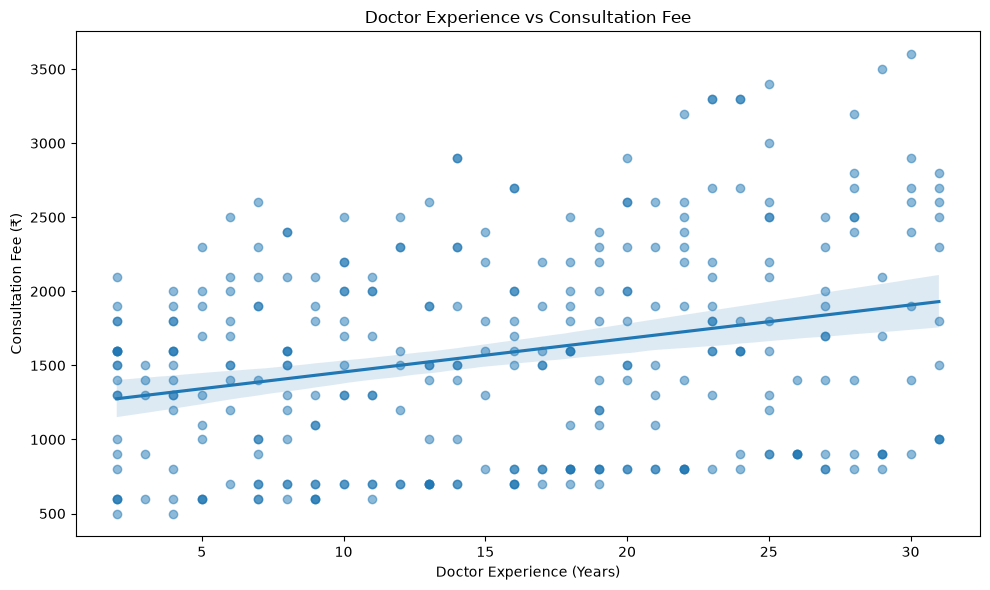

In [69]:
# Visualizations 

plt.figure(figsize=(10, 6))

sns.regplot(
    data=Apollo_doctor,
    x="experience_years",
    y="consultation_fee",
    scatter_kws={"alpha": 0.5}
)

plt.title("Doctor Experience vs Consultation Fee")
plt.xlabel("Doctor Experience (Years)")
plt.ylabel("Consultation Fee (₹)")
plt.tight_layout()
plt.show()


### 📌 Insight
- Fees **rise with experience**: roughly ₹1,300 at 2 years versus ₹2,000–2,300 at 25–31 years, with some variation in between.

# Summary of Key Findings

| Area | Finding |
|---|---|
| **Overview** | 75,000 appointments, 32,705 patients; 73.70% completed, 15.45% no-show, 7.72% cancelled |
| **Volume** | About 25,000 a year; Q4 busiest, Q3 quietest |
| **Specialty risk** | Psychiatry 24.5%, Dermatology 21.3%, ENT 19.0% highest; Neurology 10.7% lowest |
| **Timing risk** | Evening 18.4%, weekends 18.7%, long lead times (15–30 days) 20.0% |
| **Channel / type** | Walk-In 20.9% and Home Visit about 26% are riskiest; Apollo App 14.2% and In-Clinic about 12% safest |
| **Reminders** | No reminder 30.16% → SMS + WhatsApp + Call 11.41% (about 62% lower) |
| **History** | Previous no-show 20.6% vs 15.6% |
| **Patients** | Repeat 8.6% vs first-time 66.8%; ages 19–45 highest; gender and chronic condition show little difference |
| **Revenue** | About ₹1.55 crore estimated loss from no-shows; Bengaluru, Delhi, Mumbai about 39% of revenue |
| **Insurance** | Out-of-pocket about ₹649 (insured) vs ₹1,138 (not insured) |
| **Doctors** | General Physician has about 27% of appointments; waiting time about 11–12.5 min everywhere; no link between duration and satisfaction; fees rise with experience |

# Recommendations

1. **Make multi-channel reminders the default.** SMS + WhatsApp + Call cuts no-shows by about 62% compared with no reminder.
2. **Target high-risk slots:** evening, weekend and long-lead-time bookings can get an extra reminder, a confirmation request or a small overbooking buffer.
3. **Focus on high-risk specialties** (Psychiatry, Dermatology, ENT) and on Walk-In, Home Visit and Video Consult bookings.
4. **Flag patients with a previous no-show** for proactive follow-up.
5. **Turn first-time patients into repeat patients** with follow-up reminders and membership offers.
6. **Encourage insurance-backed bookings,** as they reduce the patient's out-of-pocket cost.

# Notes & Limitations

- This is an **observational analysis**: patterns show association, not proven cause and effect.
- The revenue-loss figure is an **estimate** (average completed revenue × number of no-shows).
- The "More than 30 days" lead-time group has **no eligible appointments**.
- The repeat vs first-time gap (8.6% vs 66.8%) should be verified against how `repeat_visit` is defined.
- No-show rates use **Completed, No-Show and Cancelled** appointments only; scheduled ones are excluded.

---
**Author:** Your Name · your.email@example.com · [LinkedIn](https://www.linkedin.com/in/your-profile) · [GitHub](https://github.com/your-username)